# <center> Time Series Forecasting <center>

In [1]:
import numpy as np
import pandas as pd

%matplotlib inline

In [2]:
sales = pd.read_csv('Tractor-Sales.csv')

In [3]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Month-Year              144 non-null    object
 1   Number of Tractor Sold  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [4]:
sales.head()

,Month-Year,Number of Tractor Sold
0,Jan-03,141
1,Feb-03,157
2,Mar-03,185
3,Apr-03,199
4,May-03,203


In [5]:
sales.columns = ['Month_Year', 'No_Tractors_Sold']

In [6]:
sales['Month_Year'] = pd.to_datetime(sales.Month_Year, format='%b-%y')

In [7]:
sales.set_index(sales.Month_Year, inplace=True)

In [8]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 2003-01-01 to 2014-12-01
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Month_Year        144 non-null    datetime64[ns]
 1   No_Tractors_Sold  144 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 3.4 KB


In [9]:
sales['year'] = sales.Month_Year.dt.year
sales['month'] = sales.Month_Year.dt.month

In [10]:
sales.head()

,Month_Year,No_Tractors_Sold,year,month
Month_Year,,,,
2003-01-01,2003-01-01,141,2003,1
2003-02-01,2003-02-01,157,2003,2
2003-03-01,2003-03-01,185,2003,3
2003-04-01,2003-04-01,199,2003,4
2003-05-01,2003-05-01,203,2003,5


In [11]:
ts = sales.No_Tractors_Sold

<AxesSubplot:xlabel='Month_Year'>

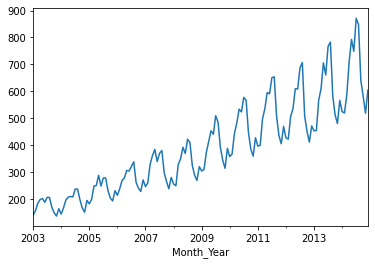

In [12]:
ts.plot()

In [13]:
pd.pivot_table?

In [14]:
pd.pivot_table(data = sales, index = 'year', columns = 'month', values = 'No_Tractors_Sold')

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2003,141,157,185,199,203,189,207,207,171,150,138,165
2004,145,168,197,208,210,209,238,238,199,168,152,196
2005,183,200,249,251,289,249,279,279,232,204,194,232
2006,215,239,270,279,307,305,322,339,263,241,229,272
2007,247,261,330,362,385,340,370,381,299,266,239,281
2008,257,250,329,350,393,370,423,410,326,289,270,321
2009,305,310,374,414,454,441,510,486,393,345,315,389
2010,358,368,444,482,534,524,578,567,447,386,360,428
2011,397,400,498,536,596,591,651,654,509,437,406,470


<AxesSubplot:xlabel='year'>

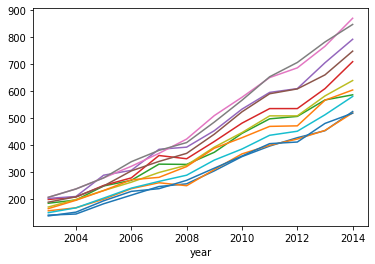

In [15]:
#Long to wide data
pd.pivot_table(data = sales, index = 'year', columns = 'month', values = 'No_Tractors_Sold').plot(legend=False)

<AxesSubplot:xlabel='month'>

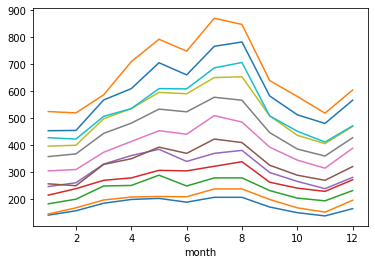

In [16]:
pd.pivot_table(data = sales, index = 'month', columns = 'year', values = 'No_Tractors_Sold').plot(legend=False)

In [17]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [18]:
seasonal_decompose?

In [19]:
#decom = seasonal_decompose(ts, model='multiplicative')
decom = seasonal_decompose(ts, model='additive')

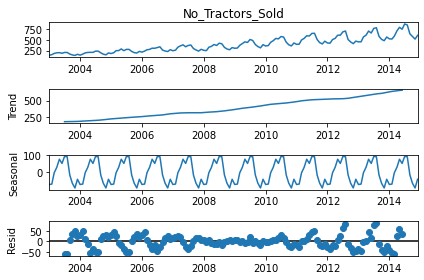

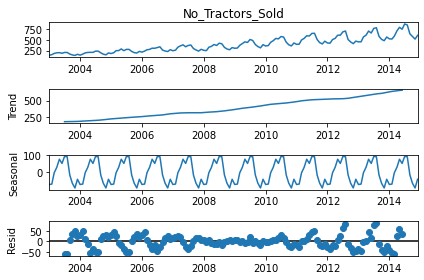

In [20]:
decom.plot()

In [21]:
pd.concat([decom.observed, decom.trend, decom.seasonal, decom.resid], axis=1).head(12)

,No_Tractors_Sold,trend,seasonal,resid
Month_Year,,,,
2003-01-01,141.0,NaN,-68.763889,NaN
2003-02-01,157.0,NaN,-66.434343,NaN
2003-03-01,185.0,NaN,-1.638889,NaN
2003-04-01,199.0,NaN,29.952020,NaN
2003-05-01,203.0,NaN,75.876263,NaN
2003-06-01,189.0,NaN,51.948232,NaN
2003-07-01,207.0,176.166667,91.584596,-60.751263
2003-08-01,207.0,176.791667,90.482323,-60.273990
2003-09-01,171.0,177.750000,-14.233586,7.483586


In [22]:
176.166667*1.236024*0.950648

207.00001654741857

In [23]:
176.166667+91.584596-60.751263

207.0

In [24]:
from statsmodels.tsa.stattools import acf, pacf_ols

In [25]:
acf(ts)

C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\stattools.py:657: FutureWarning: The default number of lags is changing from 40 tomin(int(10 * np.log10(nobs)), nobs - 1) after 0.12is released. Set the number of lags to an integer to  silence this warning.
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\stattools.py:666: FutureWarning: fft=True will become the default after the release of the 0.12 release of statsmodels. To suppress this warning, explicitly set fft=False.
  FutureWarning,


array([1.        , 0.93227225, 0.85202781, 0.77529517, 0.70383048,
       0.6278042 , 0.56094238, 0.57893406, 0.60681233, 0.63946606,
       0.6804663 , 0.73091127, 0.76575247, 0.70555818, 0.63460587,
       0.56558852, 0.50183519, 0.43173688, 0.36926281, 0.38242452,
       0.40550795, 0.43557653, 0.46949925, 0.51325504, 0.54387774,
       0.49530447, 0.43512648, 0.37720715, 0.32371582, 0.26447048,
       0.20945232, 0.21905726, 0.23925497, 0.2619118 , 0.29151722,
       0.32801019, 0.35491553, 0.31358695, 0.26116366, 0.21049862,
       0.15939473])

In [26]:
pacf_ols(ts)

C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\stattools.py:886: FutureWarning: The default number of lags is changing from 40 tomin(int(10 * np.log10(nobs)), nobs - 1) after 0.12is released. Set the number of lags to an integer to  silence this warning.
  FutureWarning,


array([ 1.        ,  0.94282542, -0.19338079,  0.04385943,  0.01926126,
        0.01370998,  0.07475455,  0.84904005, -0.10249317,  0.41605171,
        0.47255786,  0.82978844,  0.50798646, -0.76132915, -0.21328399,
        0.17472598, -0.28103267,  0.08969196,  0.01505392,  0.12151827,
        0.09053338,  0.1730479 ,  0.25529559,  0.28855185, -0.00843619,
       -0.35674915, -0.03521692,  0.08786997,  0.0074035 ,  0.09865426,
       -0.06365013,  0.27511621,  0.2639434 , -0.15944552,  0.2455883 ,
       -0.04953185,  0.08325794, -0.0483068 , -0.16124625,  0.17784005,
        0.31947992])

In [27]:
import statsmodels.tsa.api as smt

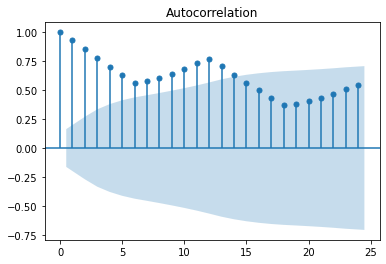

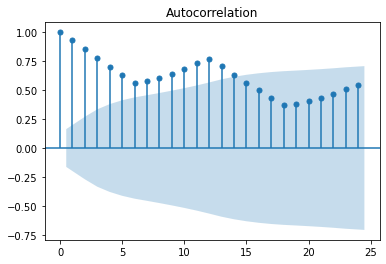

In [28]:
smt.graphics.plot_acf(ts, lags=24)

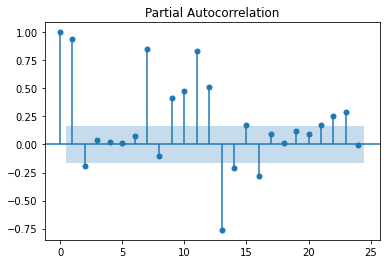

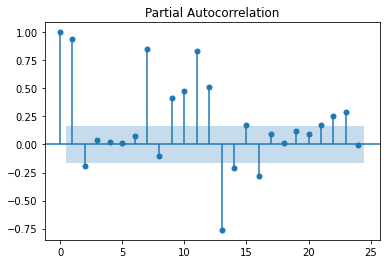

In [29]:
smt.graphics.plot_pacf(ts, lags = 24, method='ols')

In [30]:
#Is the series stationary?

# Perform Dickey-Fuller test:
from statsmodels.tsa.stattools import adfuller
adfuller(ts)   #p-value: 0.9952   , since p-value is high, the series(ts) is not stationary

(1.1088250591467401,
 0.995291241524842,
 14,
 129,
 {'1%': -3.482087964046026,
  '5%': -2.8842185101614626,
  '10%': -2.578864381347275},
 1082.5357724796872)

In [31]:
ts_ln = np.log(ts)

In [32]:
adfuller(ts_ln) #p-value = 0.41446449274910446, since p-value is high, the series(ln_ts) is not stationary

(-1.7324716814049712,
 0.41446449274910446,
 13,
 130,
 {'1%': -3.4816817173418295,
  '5%': -2.8840418343195267,
  '10%': -2.578770059171598},
 -446.8186692532702)

In [33]:
ts_diff = ts.diff().dropna()

In [34]:
adfuller(ts_diff) #p-value=0.10525012618272955, since p-value is high, the series(ts_diff) is not stationary

(-2.543480773196045,
 0.10525012618272955,
 14,
 128,
 {'1%': -3.4825006939887997,
  '5%': -2.884397984161377,
  '10%': -2.578960197753906},
 1067.8217204928187)

In [35]:
ts_ln_diff = np.log(ts).diff().dropna()

In [36]:
adfuller(ts_ln_diff)   #p-value=0.07747972836509216, since p-value is high, the series(ts_ln_diff) is not stationary

(-2.6804671199965573,
 0.07747972836509216,
 14,
 128,
 {'1%': -3.4825006939887997,
  '5%': -2.884397984161377,
  '10%': -2.578960197753906},
 -441.8932659968409)

In [37]:
ts_ln_diff2 = np.log(ts).diff(2).dropna()

In [38]:
adfuller(ts_ln_diff2)  #p-value=0.01994295010546119, since p-value<0.05, the series (ts_ln_diff2) is stationary series

(-3.200721566232404,
 0.01994295010546119,
 11,
 130,
 {'1%': -3.4816817173418295,
  '5%': -2.8840418343195267,
  '10%': -2.578770059171598},
 -434.9038941451596)

<AxesSubplot:xlabel='Month_Year'>

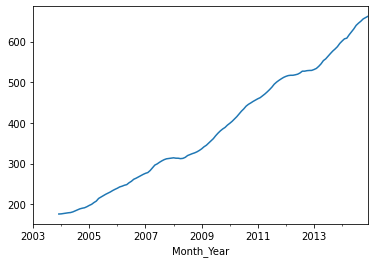

In [39]:
# Moving average

ts.rolling(window=12).mean().plot()

<AxesSubplot:xlabel='Month_Year'>

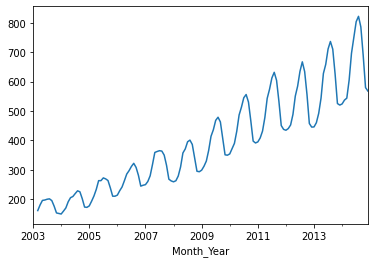

In [40]:
ts.rolling(window=3).mean().plot()

<AxesSubplot:xlabel='Month_Year'>

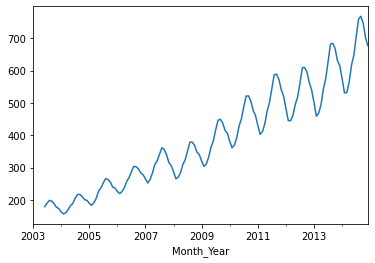

In [41]:
ts.rolling(window=6).mean().plot()

<AxesSubplot:xlabel='Month_Year'>

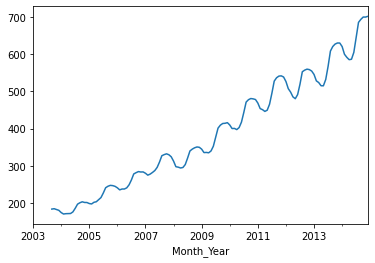

In [42]:
ts.rolling(window=9).mean().plot()

In [43]:
#ETS models
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [44]:
from sklearn.metrics import mean_absolute_error

def auto_hwm(timeseries, val_split_date, alpha=[None], beta=[None], gamma=[None], 
              trend=None, seasonal=None, periods=None, verbose=False):

    best_params = []
    actual = timeseries[val_split_date:]

    print('Evaluating Exponential Smoothing model for', len(alpha) * len(beta) * len(gamma), 'fits\n')

    for a in alpha:
        for b in beta:
            for g in gamma:

                    if(verbose == True):
                        print('Checking for', {'alpha': a, 'beta': b, 'gamma': g})

                    model = ExponentialSmoothing(timeseries, trend=trend, seasonal=seasonal, seasonal_periods=periods)
                    model.fit(smoothing_level=a, smoothing_slope=b, smoothing_seasonal=g)
                    f_cast = model.predict(model.params, start=actual.index[0])
                    score = np.where(np.float64(mean_absolute_error(actual, f_cast)/actual).mean()>0,np.float64(mean_absolute_error(actual, f_cast)/actual).mean(),0)

                    best_params.append({'alpha': a, 'beta': b, 'gamma': g, 'mae': score})

    return min(best_params, key=lambda x: x['mae'])

In [45]:
alpha = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]
beta = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]
gamma =[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]

In [46]:
ts.tail()

Month_Year
2014-08-01    848
2014-09-01    640
2014-10-01    581
2014-11-01    519
2014-12-01    605
Name: No_Tractors_Sold, dtype: int64

In [47]:
auto_hwm(ts, val_split_date ='2014-07-01' , alpha=alpha, beta=beta, gamma=gamma, 
              trend='mul', seasonal='mul', periods=12, verbose=True)

Evaluating Exponential Smoothing model for 729 fits

Checking for {'alpha': 0.1, 'beta': 0.1, 'gamma': 0.1}
Checking for {'alpha': 0.1, 'beta': 0.1, 'gamma': 0.2}
Checking for {'alpha': 0.1, 'beta': 0.1, 'gamma': 0.3}


C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be handled at model creation
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\ipykernel_launcher.py:19: FutureWarning: the 'smoothing_slope'' keyword is deprecated, use 'smoothing_trend' instead
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:80: RuntimeWarning: overflow encountered in matmul
  return err.T @ err
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be

Checking for {'alpha': 0.1, 'beta': 0.1, 'gamma': 0.4}
Checking for {'alpha': 0.1, 'beta': 0.1, 'gamma': 0.5}
Checking for {'alpha': 0.1, 'beta': 0.1, 'gamma': 0.6}
Checking for {'alpha': 0.1, 'beta': 0.1, 'gamma': 0.7}


C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be handled at model creation
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\ipykernel_launcher.py:19: FutureWarning: the 'smoothing_slope'' keyword is deprecated, use 'smoothing_trend' instead
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:80: RuntimeWarning: overflow encountered in matmul
  return err.T @ err
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be

Checking for {'alpha': 0.1, 'beta': 0.1, 'gamma': 0.8}
Checking for {'alpha': 0.1, 'beta': 0.1, 'gamma': 0.9}


...

Checking for {'alpha': 0.9, 'beta': 0.9, 'gamma': 0.2}
Checking for {'alpha': 0.9, 'beta': 0.9, 'gamma': 0.3}
Checking for {'alpha': 0.9, 'beta': 0.9, 'gamma': 0.4}
Checking for {'alpha': 0.9, 'beta': 0.9, 'gamma': 0.5}


C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be handled at model creation
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\ipykernel_launcher.py:19: FutureWarning: the 'smoothing_slope'' keyword is deprecated, use 'smoothing_trend' instead
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be handled at model creation
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\ipykernel_launcher.py:19: FutureWarning: the 'smoothing_slope'' k

Checking for {'alpha': 0.9, 'beta': 0.9, 'gamma': 0.6}
Checking for {'alpha': 0.9, 'beta': 0.9, 'gamma': 0.7}
Checking for {'alpha': 0.9, 'beta': 0.9, 'gamma': 0.8}
Checking for {'alpha': 0.9, 'beta': 0.9, 'gamma': 0.9}


C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be handled at model creation
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\ipykernel_launcher.py:19: FutureWarning: the 'smoothing_slope'' keyword is deprecated, use 'smoothing_trend' instead
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:922: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  ConvergenceWarning,
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 

{'alpha': 0.1, 'beta': 0.6, 'gamma': 0.2, 'mae': array(0.01287062)}

In [48]:
ets_model = ExponentialSmoothing(ts, trend='mul', seasonal='mul', seasonal_periods=12).fit(smoothing_level=0.1, smoothing_slope=0.6, smoothing_seasonal=0.2)

C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be handled at model creation
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\ipykernel_launcher.py:1: FutureWarning: the 'smoothing_slope'' keyword is deprecated, use 'smoothing_trend' instead
  """Entry point for launching an IPython kernel.
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:80: RuntimeWarning: overflow encountered in matmul
  return err.T @ err


In [49]:
print(ets_model.summary())

                       ExponentialSmoothing Model Results                       
Dep. Variable:         No_Tractors_Sold   No. Observations:                  144
Model:             ExponentialSmoothing   SSE                          62690.793
Optimized:                         True   AIC                            906.967
Trend:                   Multiplicative   BIC                            954.484
Seasonal:                Multiplicative   AICC                           912.439
Seasonal Periods:                    12   Date:                 Fri, 16 Jul 2021
Box-Cox:                          False   Time:                         09:14:33
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level               0.1000000                alpha                False
smoothing_trend          

In [50]:
ets_model.forecast(24)

2015-01-01    560.654351
2015-02-01    566.092417
2015-03-01    682.239654
2015-04-01    750.246799
2015-05-01    838.124926
2015-06-01    800.133635
2015-07-01    903.656152
2015-08-01    896.283512
2015-09-01    680.452281
2015-10-01    598.145776
2015-11-01    546.226934
2015-12-01    640.307029
2016-01-01    591.320832
2016-02-01    597.056347
2016-03-01    719.556567
2016-04-01    791.283543
2016-05-01    883.968398
2016-06-01    843.899072
2016-07-01    953.084029
2016-08-01    945.308122
2016-09-01    717.671428
2016-10-01    630.862950
2016-11-01    576.104270
2016-12-01    675.330325
Freq: MS, dtype: float64

In [51]:
train = ts['2003-01-01':'2014-06-01']  # Model on the train data

In [52]:
test = ts['2014-07-01':]

In [53]:
ets_model = ExponentialSmoothing(train, trend='mul', seasonal='mul', seasonal_periods=12).fit(smoothing_level=0.1, smoothing_slope=0.6, smoothing_seasonal=0.2)

C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be handled at model creation
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\ipykernel_launcher.py:1: FutureWarning: the 'smoothing_slope'' keyword is deprecated, use 'smoothing_trend' instead
  """Entry point for launching an IPython kernel.
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:80: RuntimeWarning: overflow encountered in matmul
  return err.T @ err


In [54]:
f_cast = ets_model.forecast(6)

In [55]:
f_cast

2014-07-01    853.495747
2014-08-01    848.824472
2014-09-01    643.528686
2014-10-01    558.915390
2014-11-01    512.691501
2014-12-01    599.839903
Freq: MS, dtype: float64

In [56]:
test

Month_Year
2014-07-01    871
2014-08-01    848
2014-09-01    640
2014-10-01    581
2014-11-01    519
2014-12-01    605
Name: No_Tractors_Sold, dtype: int64

In [57]:
print('test error', np.mean(np.abs(test - f_cast)/test))

test error 0.0142130209605631


In [58]:
pred = ets_model.fittedvalues['2013-07-01':]

In [59]:
actual = train['2013-07-01':]

In [60]:
print('train error',np.mean(np.abs(actual-pred)/actual))

train error 0.03571833697219147


In [61]:
ets_model = ExponentialSmoothing(ts, trend='mul', seasonal='mul', seasonal_periods=12).fit(smoothing_level=0.1, smoothing_slope=0.6, smoothing_seasonal=0.2)

C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:429: FutureWarning: After 0.13 initialization must be handled at model creation
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\ipykernel_launcher.py:1: FutureWarning: the 'smoothing_slope'' keyword is deprecated, use 'smoothing_trend' instead
  """Entry point for launching an IPython kernel.
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\holtwinters\model.py:80: RuntimeWarning: overflow encountered in matmul
  return err.T @ err


In [62]:
ets_model.forecast(12)

2015-01-01    560.654351
2015-02-01    566.092417
2015-03-01    682.239654
2015-04-01    750.246799
2015-05-01    838.124926
2015-06-01    800.133635
2015-07-01    903.656152
2015-08-01    896.283512
2015-09-01    680.452281
2015-10-01    598.145776
2015-11-01    546.226934
2015-12-01    640.307029
Freq: MS, dtype: float64

In [63]:
#ts - total data
#train, test

adfuller(np.log(ts).diff(2).dropna())

# original = ts
# stationary series = ln_ts_diff2
# input for ARIMA: Yt = ln_ts, d=2

(-3.200721566232404,
 0.01994295010546119,
 11,
 130,
 {'1%': -3.4816817173418295,
  '5%': -2.8840418343195267,
  '10%': -2.578770059171598},
 -434.9038941451596)

In [64]:
ln_ts_diff2 = np.log(ts).diff(2).dropna()   #Stationary series

ln_ts = np.log(ts)  #input to model

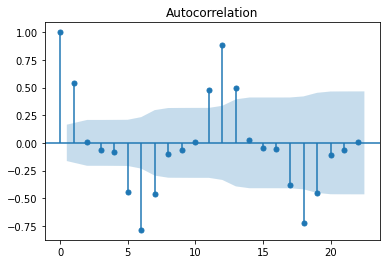

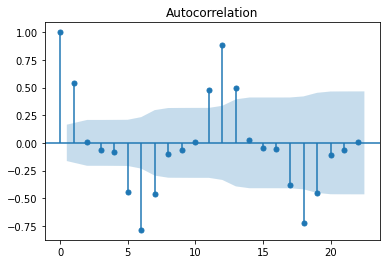

In [65]:
smt.graphics.plot_acf(ln_ts_diff2)

In [66]:
smt.acf(ln_ts_diff2)

C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\stattools.py:657: FutureWarning: The default number of lags is changing from 40 tomin(int(10 * np.log10(nobs)), nobs - 1) after 0.12is released. Set the number of lags to an integer to  silence this warning.
  FutureWarning,
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\stattools.py:666: FutureWarning: fft=True will become the default after the release of the 0.12 release of statsmodels. To suppress this warning, explicitly set fft=False.
  FutureWarning,


array([ 1.        ,  0.54194956,  0.0099027 , -0.06510041, -0.08202942,
       -0.44195862, -0.78692599, -0.4636863 , -0.09665969, -0.0601077 ,
        0.00524666,  0.4785164 ,  0.88622673,  0.49475938,  0.0267353 ,
       -0.04486359, -0.05689867, -0.38465263, -0.72315241, -0.45001557,
       -0.1071293 , -0.06157504,  0.00963746,  0.43567694,  0.79739755,
        0.45209522,  0.03586219, -0.02320116, -0.03386362, -0.33849582,
       -0.65328285, -0.40363669, -0.10006952, -0.07936729, -0.01300483,
        0.37328978,  0.70972452,  0.41909235,  0.05053688,  0.00973229,
       -0.00237005])

In [67]:
# Series is seasonal - SARIMA Model
# value of q = 1, Q=1
# q value foudnd based after which value of lag, the correlations becoming zero or crossing zero (positive to negative or negative to positive)

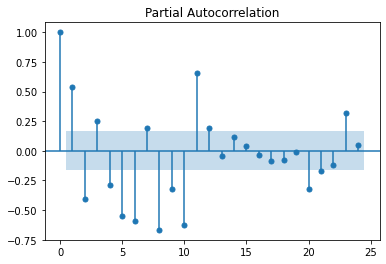

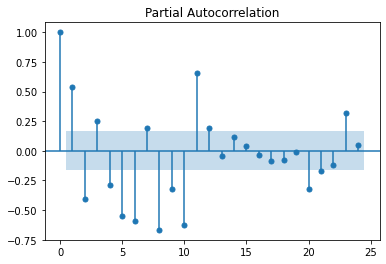

In [68]:
#PACF
smt.graphics.plot_pacf(ln_ts_diff2, lags = 24, method='ols')

In [69]:
#Based on PACF - you can find the value of p =1, P=1

In [70]:
#Box-Jenkins process - helps to get approximate values of p,d,q 

#using above p,d,q values, we will come up with ranges to check which value is best value

#Model = SARIMA
#Model input time series = ln_ts
#(p,d,q) = (1,2,1)
#(P,D,Q,T) = (1,0,1,12)

In [71]:
train = ln_ts[:'2014-06-01']
test = ln_ts['2014-07-01':]

In [72]:
import statsmodels.api as sm

model = sm.tsa.statespace.SARIMAX(train, order = (1,2,1), seasonal_order= (1,0,1,12),
                                             enforce_stationarity=False,
                                             enforce_invertibility=False).fit()

C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:527: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  % freq, ValueWarning)
C:\Users\om\Anaconda3\lib\site-packages\statsmodels\base\model.py:568: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  ConvergenceWarning)


In [73]:
print(model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                   No_Tractors_Sold   No. Observations:                  138
Model:             SARIMAX(1, 2, 1)x(1, 0, 1, 12)   Log Likelihood                 222.077
Date:                            Fri, 16 Jul 2021   AIC                           -434.155
Time:                                    09:14:37   BIC                           -420.134
Sample:                                01-01-2003   HQIC                          -428.460
                                     - 06-01-2014                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3577      0.075     -4.762      0.000      -0.505      -0.210
ma.L1         -1.0000     58.354   

In [74]:
f_cast = np.exp(model.forecast(6))

In [75]:
act = np.exp(test)

In [76]:
print('test_error:',np.mean(np.abs(act-f_cast)/act))

test_error: 0.01828716254259219


In [77]:
pred = np.exp(model.fittedvalues)['2013-07-01':]
act = np.exp(ln_ts)['2013-07-01':]

In [78]:
print('train_error_last1year:', np.mean(np.abs(act-pred)/act))

train_error_last1year: 0.0291906361459106


In [79]:
import sys
import itertools
import warnings

def auto_arima(timeseries, regressors=None, p=range(0, 2), d=range(0, 2), q=range(0, 2),
              P=range(0, 2), D=range(0, 1), Q=range(0, 2)):

    # Generate all different combinations of p, d and q triplets
    pdq = list(itertools.product(p, d, q))

    # Generate all different combinations of seasonal p, q and q triplets
    seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(P, D, Q))]
    
    warnings.filterwarnings("ignore") # specify to ignore warning messages

    best_aic = np.inf
    best_pdq = None
    best_seasonal_pdq = None
    best_results = None
    
    for param in pdq:
        for param_seasonal in seasonal_pdq:

            try:
                temp_model = sm.tsa.statespace.SARIMAX(endog=timeseries,
                                                 exog=regressors,
                                                 order = param,
                                                 seasonal_order = param_seasonal,
                                                 enforce_stationarity=False,
                                                 enforce_invertibility=False)
                temp_results = temp_model.fit()

                print("SARIMAX{}x{}12 - AIC:{}".format(param, param_seasonal, temp_results.aic))
                
                if temp_results.aic < best_aic:
                    best_aic = temp_results.aic
                    best_pdq = param
                    best_seasonal_pdq = param_seasonal
                    best_results = temp_results
                
            except:
                #print("Unexpected error:", sys.exc_info()[0])
                continue
    print("Best SARIMAX{}x{}12 model - AIC:{}".format(best_pdq, best_seasonal_pdq, best_aic))
    print(best_results.summary().tables[0])
    print(best_results.summary().tables[1])
    #return best_results

In [80]:
best_results = auto_arima(ln_ts,  p=range(0, 3), d=range(2, 3), q=range(0, 3),
                         P=range(0, 3), D=range(0, 2), Q=range(0, 3))    #Number of models = 3*1*3*3*2*3 = 162

SARIMAX(0, 2, 0)x(0, 0, 0, 12)12 - AIC:-94.33654573139205
SARIMAX(0, 2, 0)x(0, 0, 1, 12)12 - AIC:-179.84996270481906
SARIMAX(0, 2, 0)x(0, 0, 2, 12)12 - AIC:-199.45343378320064
SARIMAX(0, 2, 0)x(0, 1, 0, 12)12 - AIC:-299.1011736447878
SARIMAX(0, 2, 0)x(0, 1, 1, 12)12 - AIC:-300.63982039526576
SARIMAX(0, 2, 0)x(0, 1, 2, 12)12 - AIC:-283.9898559018435
SARIMAX(0, 2, 0)x(1, 0, 0, 12)12 - AIC:-306.0748603022431
SARIMAX(0, 2, 0)x(1, 0, 1, 12)12 - AIC:-330.82169834714125
SARIMAX(0, 2, 0)x(1, 0, 2, 12)12 - AIC:-293.42977943447966
SARIMAX(0, 2, 0)x(1, 1, 0, 12)12 - AIC:-287.8176302355575
SARIMAX(0, 2, 0)x(1, 1, 1, 12)12 - AIC:-297.42491085818307
SARIMAX(0, 2, 0)x(1, 1, 2, 12)12 - AIC:-284.69946007600095
SARIMAX(0, 2, 0)x(2, 0, 0, 12)12 - AIC:-288.0457908563947
SARIMAX(0, 2, 0)x(2, 0, 1, 12)12 - AIC:-296.5370571421565
SARIMAX(0, 2, 0)x(2, 0, 2, 12)12 - AIC:-301.6820174920626
SARIMAX(0, 2, 0)x(2, 1, 0, 12)12 - AIC:-283.3718768601679
SARIMAX(0, 2, 0)x(2, 1, 1, 12)12 - AIC:-285.9289930176406
SARIMAX

SARIMAX(2, 2, 1)x(2, 1, 0, 12)12 - AIC:-379.8621392735954
SARIMAX(2, 2, 1)x(2, 1, 1, 12)12 - AIC:-378.4799526744565
SARIMAX(2, 2, 1)x(2, 1, 2, 12)12 - AIC:-381.68975092816504
SARIMAX(2, 2, 2)x(0, 0, 0, 12)12 - AIC:-165.43877020865597
SARIMAX(2, 2, 2)x(0, 0, 1, 12)12 - AIC:-246.0198839983231
SARIMAX(2, 2, 2)x(0, 0, 2, 12)12 - AIC:-271.2549339939857
SARIMAX(2, 2, 2)x(0, 1, 0, 12)12 - AIC:-424.5266207609623
SARIMAX(2, 2, 2)x(0, 1, 1, 12)12 - AIC:-420.799447887157
SARIMAX(2, 2, 2)x(0, 1, 2, 12)12 - AIC:-378.13071142332313
SARIMAX(2, 2, 2)x(1, 0, 0, 12)12 - AIC:-427.54889828999467
SARIMAX(2, 2, 2)x(1, 0, 1, 12)12 - AIC:-448.910175892685
SARIMAX(2, 2, 2)x(1, 0, 2, 12)12 - AIC:-403.64444645158335
SARIMAX(2, 2, 2)x(1, 1, 0, 12)12 - AIC:-417.6222109683395
SARIMAX(2, 2, 2)x(1, 1, 1, 12)12 - AIC:-416.06027021989917
SARIMAX(2, 2, 2)x(1, 1, 2, 12)12 - AIC:-377.73510221652765
SARIMAX(2, 2, 2)x(2, 0, 0, 12)12 - AIC:-414.9577246642848
SARIMAX(2, 2, 2)x(2, 0, 1, 12)12 - AIC:-412.820463213467
SARIMAX(2,

In [81]:
import statsmodels.api as sm

model = sm.tsa.statespace.SARIMAX(train, order = (1,2,1), seasonal_order= (1,0,1,12),
                                             enforce_stationarity=False,
                                             enforce_invertibility=False).fit()

print(model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                   No_Tractors_Sold   No. Observations:                  138
Model:             SARIMAX(1, 2, 1)x(1, 0, 1, 12)   Log Likelihood                 222.077
Date:                            Fri, 16 Jul 2021   AIC                           -434.155
Time:                                    09:17:56   BIC                           -420.134
Sample:                                01-01-2003   HQIC                          -428.460
                                     - 06-01-2014                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3577      0.075     -4.762      0.000      -0.505      -0.210
ma.L1         -1.0000     58.354   

In [82]:
f_cast = np.exp(model.forecast(6))

In [83]:
act = np.exp(test)

In [84]:
print('test_error:',np.mean(np.abs(act-f_cast)/act))

test_error: 0.01828716254259219


In [85]:
pred = np.exp(model.fittedvalues)['2013-07-01':]
act = np.exp(ln_ts)['2013-07-01':]

In [86]:
print('train_error_last1year:', np.mean(np.abs(act-pred)/act))

train_error_last1year: 0.0291906361459106


In [87]:
import statsmodels.api as sm

model = sm.tsa.statespace.SARIMAX(ln_ts, order = (1,2,1), seasonal_order= (1,0,1,12),
                                             enforce_stationarity=False,
                                             enforce_invertibility=False).fit()

In [88]:
f_cast = np.exp(model.forecast(12))

In [89]:
ts

Month_Year
2003-01-01    141
2003-02-01    157
2003-03-01    185
2003-04-01    199
2003-05-01    203
             ... 
2014-08-01    848
2014-09-01    640
2014-10-01    581
2014-11-01    519
2014-12-01    605
Name: No_Tractors_Sold, Length: 144, dtype: int64

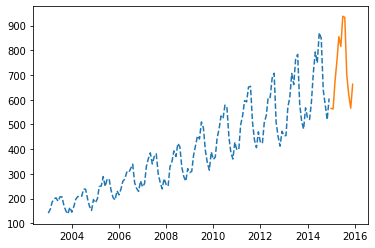

In [90]:
import matplotlib.pyplot as plt
plt.plot(ts, '--', label='obs')
plt.plot(f_cast, '-', label=f_cast)

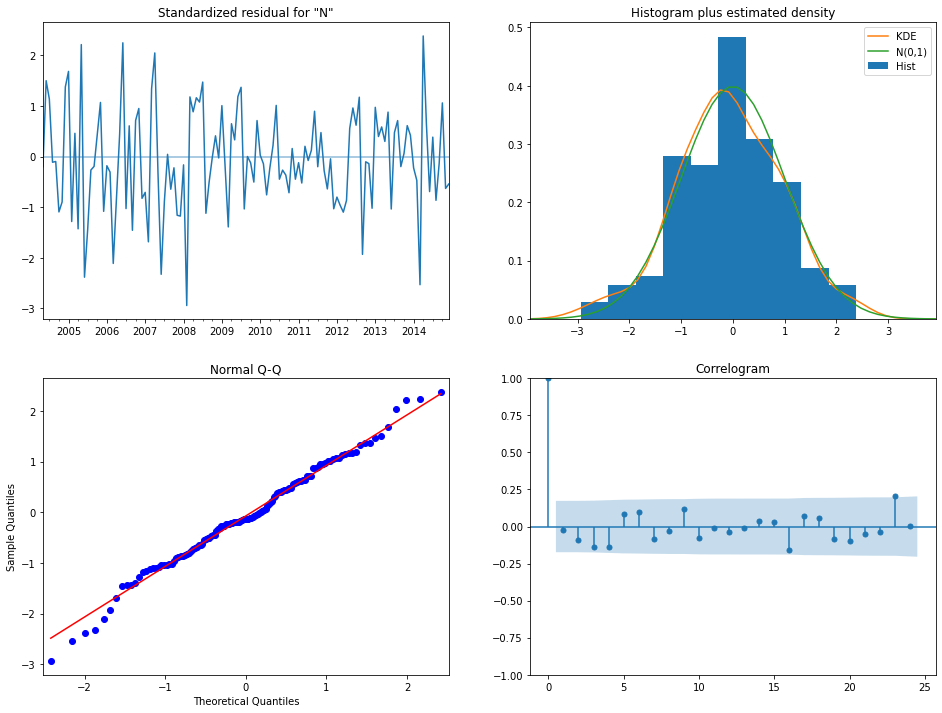

In [91]:
model.plot_diagnostics(lags=24, figsize=(16,12))
plt.show()

#Errors should follow normal distribution
#ACF of Errors - Error series should be white noise/random walk- There is no auto correlation among errors

In [92]:
#Multivariate Time series

In [93]:
data = pd.read_csv('Sales-and-Marketing.csv')

In [94]:
data.head()

,Time Period,Sales,Marketing Expense
0,Jan-11,397,486.64
1,Feb-11,400,501.80
2,Mar-11,498,437.09
3,Apr-11,536,565.16
4,May-11,596,744.15


In [95]:
data.columns = ['Month', 'Sales', 'MS']

In [98]:
data['Month'] =pd.to_datetime(data.Month, format='%b-%y')

In [101]:
data.set_index(data.Month, inplace=True)

In [102]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48 entries, 2011-01-01 to 2014-12-01
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Month   48 non-null     datetime64[ns]
 1   Sales   48 non-null     int64         
 2   MS      48 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 1.5 KB


In [104]:
adfuller(data.Sales.diff(1).dropna())

(-7.015650419745929,
 6.743731035461958e-10,
 10,
 36,
 {'1%': -3.626651907578875,
  '5%': -2.9459512825788754,
  '10%': -2.6116707716049383},
 361.3167752934367)

In [105]:
sales_diff = data.Sales.diff(1).dropna()

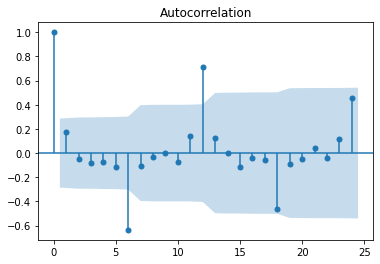

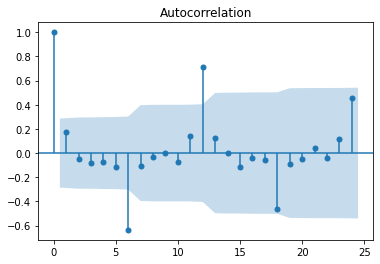

In [106]:
smt.graphics.plot_acf(sales_diff, lags=24)

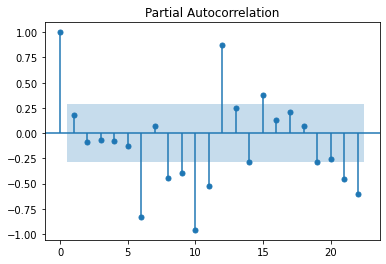

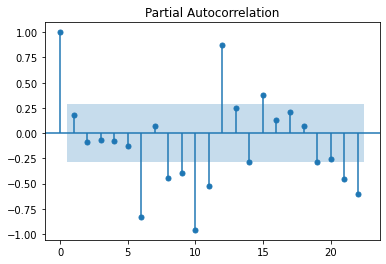

In [155]:
smt.graphics.plot_pacf(sales_diff, lags = 22, method='ols')

In [111]:
#p=1, q=1, d=1, Yt=Sales, SARIMA, P=1, D=0, Q =1

In [115]:
data['MS_Lag1'] = data.MS.shift(1)
data['MS_Lag2'] = data.MS.shift(2)
data['MS_Lag3'] = data.MS.shift(3)
data['MS_Lag4'] = data.MS.shift(4)

In [116]:
data.head(10)

,Month,Sales,MS,MS_Lag1,MS_Lag2,MS_Lag3,MS_Lag4
Month,,,,,,,
2011-01-01,2011-01-01,397,486.64,NaN,NaN,NaN,NaN
2011-02-01,2011-02-01,400,501.80,486.64,NaN,NaN,NaN
2011-03-01,2011-03-01,498,437.09,501.80,486.64,NaN,NaN
2011-04-01,2011-04-01,536,565.16,437.09,501.80,486.64,NaN
2011-05-01,2011-05-01,596,744.15,565.16,437.09,501.80,486.64
2011-06-01,2011-06-01,591,548.74,744.15,565.16,437.09,501.80
2011-07-01,2011-07-01,651,650.21,548.74,744.15,565.16,437.09
2011-08-01,2011-08-01,654,777.51,650.21,548.74,744.15,565.16
2011-09-01,2011-09-01,509,547.11,777.51,650.21,548.74,744.15


In [118]:
data['2011-05-01':].corr()

,Sales,MS,MS_Lag1,MS_Lag2,MS_Lag3,MS_Lag4
Sales,1.000000,0.807838,0.585169,0.262011,-0.056909,-0.257012
MS,0.807838,1.000000,0.626329,0.380395,0.140597,-0.130755
MS_Lag1,0.585169,0.626329,1.000000,0.622385,0.380459,0.145967
MS_Lag2,0.262011,0.380395,0.622385,1.000000,0.625423,0.398619
MS_Lag3,-0.056909,0.140597,0.380459,0.625423,1.000000,0.634986
MS_Lag4,-0.257012,-0.130755,0.145967,0.398619,0.634986,1.000000


In [120]:
X = data['2011-05-01':][['MS', 'MS_Lag1', 'MS_Lag2']]
ts = data['2011-05-01':].Sales

In [121]:
model = sm.tsa.statespace.SARIMAX(ts,
                                      exog = X,
                                      order=(1, 1, 1),
                                      seasonal_order=(1, 0, 1, 12),
                                      enforce_stationarity=False,
                                      enforce_invertibility=False).fit()

In [122]:
print(model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                   44
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood                -997.871
Date:                            Fri, 16 Jul 2021   AIC                           2011.743
Time:                                    09:57:52   BIC                           2022.681
Sample:                                05-01-2011   HQIC                          2015.169
                                     - 12-01-2014                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
MS             0.2436   1.01e+04   2.41e-05      1.000   -1.98e+04    1.98e+04
MS_Lag1        0.2163   9316.559   

In [ ]:
import sys

def auto_arima(timeseries, regressors=None, p=range(0, 2), d=range(0, 2), q=range(0, 2),
              P=range(0, 2), D=range(0, 1), Q=range(0, 2)):

    # Generate all different combinations of p, d and q triplets
    pdq = list(itertools.product(p, d, q))

    # Generate all different combinations of seasonal p, q and q triplets
    seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(P, D, Q))]
    
    warnings.filterwarnings("ignore") # specify to ignore warning messages

    best_aic = np.inf
    best_pdq = None
    best_seasonal_pdq = None
    best_results = None
    
    for param in pdq:
        for param_seasonal in seasonal_pdq:

            try:
                temp_model = sm.tsa.statespace.SARIMAX(endog=timeseries,
                                                 exog=regressors,
                                                 order = param,
                                                 seasonal_order = param_seasonal,
                                                 enforce_stationarity=False,
                                                 enforce_invertibility=False)
                temp_results = temp_model.fit()

                print("SARIMAX{}x{}12 - AIC:{}".format(param, param_seasonal, temp_results.aic))
                
                if temp_results.aic < best_aic:
                    best_aic = temp_results.aic
                    best_pdq = param
                    best_seasonal_pdq = param_seasonal
                    best_results = temp_results
                
            except:
                #print("Unexpected error:", sys.exc_info()[0])
                continue
    print("Best SARIMAX{}x{}12 model - AIC:{}".format(best_pdq, best_seasonal_pdq, best_aic))
    print(best_results.summary().tables[0])
    print(best_results.summary().tables[1])

In [141]:
best_results = auto_arima(ts, X, p=range(0, 2), d=range(0, 2), q=range(0, 2),
                         P=range(0, 2), D=range(0, 2), Q=range(0, 2))

SARIMAX(0, 0, 0)x(0, 0, 0, 12)12 - AIC:510.82257049505614
SARIMAX(0, 0, 0)x(0, 0, 1, 12)12 - AIC:1129.7664337056262
SARIMAX(0, 0, 0)x(0, 1, 0, 12)12 - AIC:335.1913471280424
SARIMAX(0, 0, 0)x(0, 1, 1, 12)12 - AIC:211.12457548564083
SARIMAX(0, 0, 0)x(1, 0, 0, 12)12 - AIC:310.03587577877454
SARIMAX(0, 0, 0)x(1, 0, 1, 12)12 - AIC:1460.668894908601
SARIMAX(0, 0, 0)x(1, 1, 0, 12)12 - AIC:218.41552509116428
SARIMAX(0, 0, 0)x(1, 1, 1, 12)12 - AIC:204.0496812578056
SARIMAX(0, 0, 1)x(0, 0, 0, 12)12 - AIC:486.81113348449617
SARIMAX(0, 0, 1)x(0, 0, 1, 12)12 - AIC:2108.488998054045
SARIMAX(0, 0, 1)x(0, 1, 0, 12)12 - AIC:311.23144512494304
SARIMAX(0, 0, 1)x(0, 1, 1, 12)12 - AIC:195.97038199410287
SARIMAX(0, 0, 1)x(1, 0, 0, 12)12 - AIC:306.13852106891443
SARIMAX(0, 0, 1)x(1, 0, 1, 12)12 - AIC:2265.727651950951
SARIMAX(0, 0, 1)x(1, 1, 0, 12)12 - AIC:214.87806390169746
SARIMAX(0, 0, 1)x(1, 1, 1, 12)12 - AIC:190.63021542887603
SARIMAX(0, 1, 0)x(0, 0, 0, 12)12 - AIC:488.132351018949
SARIMAX(0, 1, 0)x(0, 

In [142]:
model = sm.tsa.statespace.SARIMAX(ts,
                                      exog = X,
                                      order=(0, 1, 1),
                                      seasonal_order=(1, 1, 1, 12),
                                      enforce_stationarity=False,
                                      enforce_invertibility=False).fit()

In [143]:
act = data.Sales['2014-01-01':]
pred = model.fittedvalues['2014-01-01':]

In [144]:
model.fittedvalues

Month
2011-05-01     92.248118
2011-06-01    586.081958
2011-07-01    620.726308
2011-08-01    642.248942
2011-09-01    639.782740
2011-10-01    511.337240
2011-11-01    434.973372
2011-12-01    373.937448
2012-01-01    486.015203
2012-02-01    410.520351
2012-03-01    435.538062
2012-04-01    493.325968
2012-05-01    816.974629
2012-06-01    633.458559
2012-07-01    622.336376
2012-08-01    735.523891
2012-09-01    581.704452
2012-10-01    464.383978
2012-11-01    399.660675
2012-12-01    496.365016
2013-01-01    389.272410
2013-02-01    479.084782
2013-03-01    501.382815
2013-04-01    617.833249
2013-05-01    760.380192
2013-06-01    718.824391
2013-07-01    751.947549
2013-08-01    761.931267
2013-09-01    602.106957
2013-10-01    518.802502
2013-11-01    487.759992
2013-12-01    561.806406
2014-01-01    520.064058
2014-02-01    554.974319
2014-03-01    632.348876
2014-04-01    678.901603
2014-05-01    783.005778
2014-06-01    725.540600
2014-07-01    848.637349
2014-08-01    860.2

In [146]:
print('Training Error:', np.mean(np.abs(act-pred)/act))

Training Error: 0.030543855093260686


In [148]:
#Forecast for next one year
Future_mkt_spend = {
    '2015-01-01' : [600, 559.75, 527.60],
    '2015-02-01' : [550, 600, 559.75],
    '2015-03-01' : [700, 550, 600],
    '2015-04-01' : [590, 700, 550],
    '2015-05-01' : [480, 590, 700],
    '2015-06-01' : [520, 480, 590],
    '2015-07-01' : [800, 520, 480],
    '2015-08-01' : [675, 800, 520],
    '2015-09-01' : [820, 675, 800],
    '2015-10-01' : [710, 820, 675],
    '2015-11-01' : [550, 710, 820],
    '2015-12-01' : [590, 550, 710]
}

In [150]:
Future_mkt_spend = pd.DataFrame(Future_mkt_spend).T

In [151]:
Future_mkt_spend

,0,1,2
2015-01-01,600.0,559.75,527.60
2015-02-01,550.0,600.00,559.75
2015-03-01,700.0,550.00,600.00
2015-04-01,590.0,700.00,550.00
2015-05-01,480.0,590.00,700.00
2015-06-01,520.0,480.00,590.00
2015-07-01,800.0,520.00,480.00
2015-08-01,675.0,800.00,520.00
2015-09-01,820.0,675.00,800.00
2015-10-01,710.0,820.00,675.00


In [152]:
Future_mkt_spend.columns = ['MS', 'MS_Lag1', 'MS_Lag2']

In [153]:
model.forecast(steps=12, exog = Future_mkt_spend)

2015-01-01    604.798080
2015-02-01    551.878313
2015-03-01    665.576974
2015-04-01    755.278795
2015-05-01    834.242346
2015-06-01    774.968300
2015-07-01    904.230439
2015-08-01    849.943075
2015-09-01    698.316383
2015-10-01    642.821025
2015-11-01    577.849807
2015-12-01    679.104206
Freq: MS, Name: predicted_mean, dtype: float64